# Solar filament segmentation: reproduce the final submission (public LB 0.37)

This notebook rebuilds the submitted Kaggle CSV from the model weights stored in this repository, **without
retraining**, and walks through the whole pipeline:

5-fold stage-1 U-Net -> existence gate (p > 0.5, >= 500 px) -> R2 native-resolution refinement of the candidates that
overlap it -> assembly -> cleanup -> SE2 (small fragments redrawn by R2 and added by a learned per-annotator PQ gain,
threshold 0.12744). Weights: `weights/b0_fold{0..4}.pt`, `r2_final.pt`, `se2_scorer.pt`. Reference CSV:
`reference/submission_r2b0_se2.csv`.

How every stage was validated is in `docs/validation.md`. Two decisions were post hoc and are stated there: R2
(it failed two conditions of its pre-registered rule) and the SE2 threshold (chosen by the leaderboard-type scorer V1
after an exploratory sweep had been seen; at this threshold SE2 does not pass its pre-registered rule).

1. locate the test images and rebuild the seven checkpoints from their parts in `weights/` (every checksum is verified),
2. show the stages of the pipeline on one test image, and the code of every step (2b),
3. the whole pipeline: how the models were trained, validated and selected (records in `records/`), the exact
   training commands (a gated cell; training is not re-run), and the efficiency figures,
4. predict the test images and write the submission CSV (`filament_id,segmentation_rle`),
5. check the file format and compare it, filament by filament, with the reference CSV (the CSV that was submitted).

**Data.** Unzip the competition data (`filament-segmentation-2026.zip`) in the repository root so that
`MAGFiLO_1.0_Kaggle_2026/test/test_images/*.jpeg` exists, or set `FILSEG_DATA` to the folder that contains it.
Only the 180 test images are read. No annotations are read.

**Options (environment variables).** `FILSEG_DATA` (data folder), `FILSEG_OUT` (output CSV, default
`outputs/submission_r2b0_se2.csv`), `FILSEG_N_LIMIT` (only the first N test images, default 0 = all), `FILSEG_THREADS`
(CPU threads for torch, default = torch's default).

**Runtime.** On a GPU with bf16 support (compute capability 8 or higher) about 3.4 s per image (about 10 min for the
180 images on an RTX A6000). On CPU only about 14 s per image with 4 threads. On the A6000 the output is
byte-identical to the reference; on CPU (fp32 instead of bf16) a few pixels close to a threshold can flip (section 5).

In [1]:
import os
os.environ.setdefault("NUMPY_MADVISE_HUGEPAGE", "0")   # harmless elsewhere; avoids slow THP compaction on some Linux hosts
import sys, time, json, platform
from pathlib import Path

# repository root = first folder upwards that contains weights/SHA256SUMS (works from the repo root or notebooks/)
REPO = Path(os.environ["FILSEG_REPO"]) if "FILSEG_REPO" in os.environ else \
    next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "weights" / "SHA256SUMS").is_file())
sys.path.insert(0, str(REPO / "src"))

import numpy as np, torch, cv2
import filseg_infer as K          # stage 1: model, pre-processing, probability map, RLE (self-contained)
import filseg_infer_r2b0 as R2B0  # existence gate, candidates, R2_final refinement, assembly, cleanup (self-contained)
import filseg_infer_se as SE      # SE2: small-fragment existence scoring, add-only (self-contained)
import reproduce_utils as U       # weights, data discovery, comparison, figures

# competition data: found automatically at the usual places (U.locate_data); to use another folder, set FILSEG_DATA
# or write it here, e.g. DATA = Path("/path/to/MAGFiLO_1.0_Kaggle_2026")
DATA = Path(os.environ["FILSEG_DATA"]) if "FILSEG_DATA" in os.environ else U.locate_data(REPO)
OUT_CSV = Path(os.environ.get("FILSEG_OUT", REPO / "outputs" / "submission_r2b0_se2.csv"))
REF_CSV = REPO / "reference" / "submission_r2b0_se2.csv"
N_LIMIT = int(os.environ.get("FILSEG_N_LIMIT", "0"))
if int(os.environ.get("FILSEG_THREADS", "0")) > 0:
    torch.set_num_threads(int(os.environ["FILSEG_THREADS"]))

TEST_DIR = U.find_test_dir(DATA)
IMAGES = U.list_test_images(TEST_DIR, N_LIMIT)
rel = lambda p: os.path.relpath(p, REPO)
print("final pipeline: 5-fold stage 1 -> existence gate -> R2_final refinement -> assembly -> cleanup -> SE2")
print("python", platform.python_version(), "| torch", torch.__version__, "| numpy", np.__version__, "| opencv", cv2.__version__)
print("platform", platform.platform(), "| torch threads", torch.get_num_threads())
print("cuda available:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
print(f"test images: {len(IMAGES)} of {len(U.list_test_images(TEST_DIR))} (FILSEG_N_LIMIT={N_LIMIT})")
data_dir = TEST_DIR.parent.parent
print("data:", rel(data_dir) if REPO in data_dir.parents else data_dir, "| output:", rel(OUT_CSV), "| reference:", rel(REF_CSV))

final pipeline: 5-fold stage 1 -> existence gate -> R2_final refinement -> assembly -> cleanup -> SE2
python 3.13.13 | torch 2.6.0+cu124 | numpy 2.5.4 | opencv 5.0.0
platform Linux-5.15.0-139-generic-x86_64-with-glibc2.31 | torch threads 4
cuda available: True NVIDIA RTX A6000
test images: 180 of 180 (FILSEG_N_LIMIT=0)
data: MAGFiLO_1.0_Kaggle_2026 | output: outputs/submission_r2b0_se2.csv | reference: reference/submission_r2b0_se2.csv


## 1. Model weights stored in this repository

Seven fp32 `state_dict` checkpoints:
- the five stage-1 fold models `b0_fold{0..4}.pt` (U-Net, ResNet-101 encoder, 1 input channel, 206,654,336 bytes each);
- the refinement model `r2_final.pt` (the same U-Net with 10 input channels, 206,767,232 bytes);
- the SE2 scorer `se2_scorer.pt`: ResNet-101 stem + layer1 + layer2, 4 input channels, 5,882,364 bytes.

GitHub rejects files over 100 MiB, so each checkpoint is stored in plain Git as byte-range parts under 50 MB
(`weights/*.partNN`) with a manifest (`*.manifest.json`). The cell below checks the size and SHA-256 of every part,
concatenates the parts, checks the SHA-256 of each whole file against `weights/SHA256SUMS` and writes `weights/*.pt`
(git-ignored). These are byte-identical to the files the training runs wrote (`weights/README.md`).

In [2]:
t0 = time.time()
WEIGHTS = U.prepare_weights(REPO / "weights")
B0_WEIGHTS = [p for p in WEIGHTS if p.name.startswith("b0_fold")]     # b0_fold0..4.pt (sorted)
R2_WEIGHT = REPO / "weights" / "r2_final.pt"
SE2_WEIGHT = REPO / "weights" / "se2_scorer.pt"
assert len(B0_WEIGHTS) == 5 and R2_WEIGHT in WEIGHTS and SE2_WEIGHT in WEIGHTS and len(WEIGHTS) == 7
print(f"{len(WEIGHTS)} checkpoints verified in {time.time() - t0:.1f} s: 5 stage-1 fold models, R2_final, SE2 scorer")

b0_fold0.pt: 206,654,336 bytes, sha256 d7ac64c602606e20... OK (rebuilt from 5 parts)


b0_fold1.pt: 206,654,336 bytes, sha256 5bd418d8d909a3bb... OK (rebuilt from 5 parts)


b0_fold2.pt: 206,654,336 bytes, sha256 3c17ca1c2c8924c3... OK (rebuilt from 5 parts)


b0_fold3.pt: 206,654,336 bytes, sha256 c26cfa50682c9ee3... OK (rebuilt from 5 parts)


b0_fold4.pt: 206,654,336 bytes, sha256 4bdc5e35cd3c8c6e... OK (rebuilt from 5 parts)


r2_final.pt: 206,767,232 bytes, sha256 922a848c845169ec... OK (rebuilt from 5 parts)
se2_scorer.pt: 5,882,364 bytes, sha256 bff904dee9409a27... OK (rebuilt from 1 parts)
7 checkpoints verified in 6.7 s: 5 stage-1 fold models, R2_final, SE2 scorer


## 2. Pipeline

**Pre-processing.** Each 2048x2048 single-channel H-alpha JPEG is cropped to the solar-disk window `[120:1928]^2`
(1808x1808; nothing outside it is ever annotated). The crop is resized to 1024x1024 with `INTER_AREA` and normalised
as `(x/255 - 0.30) / 0.22`.

**Stage 1.** U-Net with a ResNet-101 encoder, 1 input channel, 1 output channel. The architecture is identical to
`segmentation_models_pytorch` 0.6.0 `Unet("resnet101", in_channels=1, classes=1)` and is re-implemented in
`src/filseg_infer.py` so that inference needs only torch and torchvision. Five models were trained with 5-fold
cross-validation grouped by 14-day observation windows (training code: `scripts/train_seg.py`; 60 epochs, the last
epoch is used). The encoder was initialised from torchvision's ImageNet ResNet-101. Only the competition training set
was used. Each model's logits are upsampled bilinearly to 1808^2 before the sigmoid and placed into a zero 2048^2
canvas; each model's probability is rounded to float16 and the float32 mean is rounded to float16 again.

**After stage 1**, `src/filseg_infer_r2b0.py` and `src/filseg_infer_se.py` (self-contained ports of the validated
code paths):
1. *Existence gate:* 8-connected components of p > 0.5 with at least 500 px (threshold and size chosen by nested CV).
2. *Candidates:* 8-connected components of the uint8-quantised map (`rint(p*255)/255 > 0.3`) with at least 20 px. A
   candidate is kept only if it overlaps an existence component by at least 1 px.
3. *Refinement:* R2_final predicts the whole filament that each kept candidate belongs to, on native-resolution
   384x384 windows covering the candidate's bounding box. Inputs: image, this candidate, stage-1 probability, the other
   candidates, the orientation (cos 2t, sin 2t) of the probability's structure tensor, and a 4x wider context (image,
   probability, this candidate, other candidates) downsampled to 384x384. The window outputs are averaged per candidate.
4. *Assembly:* each refined mask is p > 0.5; candidates whose masks overlap with IoU > 0.5 are merged into one
   filament; contested pixels go to the higher probability; filaments under 300 px are dropped.
5. *Cleanup:* in a multi-part filament, detached parts < 20 px and then parts < 5 % of the filament are removed (the
   MAGFiLO QA rule); the largest part is always kept.
6. *SE2:* the candidates that overlap a small component of p > 0.5 (100-499 px, what the 500 px gate discards) and do
   not touch the gate are redrawn by R2_final at native resolution and assembled (>= 100 px). The SE2 CNN scores each
   redrawn fragment on a 96x96 native crop (image, probability, redrawn fragment, >= 500 px components): it predicts
   the fragment's PQ gain averaged over the annotators, and the fragment is added iff the score exceeds 0.12744 =
   0.6 x PQ/2 (PQ/2 is the exact break-even point of the official per-set metric; 0.6 maximises the PQ with the
   annotation sets of an image pooled, the leaderboard-type scorer, on out-of-fold predictions of the training data
   only) and it does not overlap any filament.

The filaments are disjoint and written as COCO compressed RLE (column-major, size omitted) with
`filament_id = <image stem>_<k>`.

The next cell runs the stages on the first test image and shows them. It is only an illustration: the CSV is written
in section 4.

parameters + buffers per b0 model: 51,614,403


parameters + buffers of R2_final: 51,642,627


20120405130014Th.jpeg: stage-1 instances (p>0.5, >=500 px) 5 | candidates (p>0.3, >=20 px) 8, kept 5 | R2 windows 8 | filaments 5, areas (px): [824, 1386, 2291, 3823, 5621]


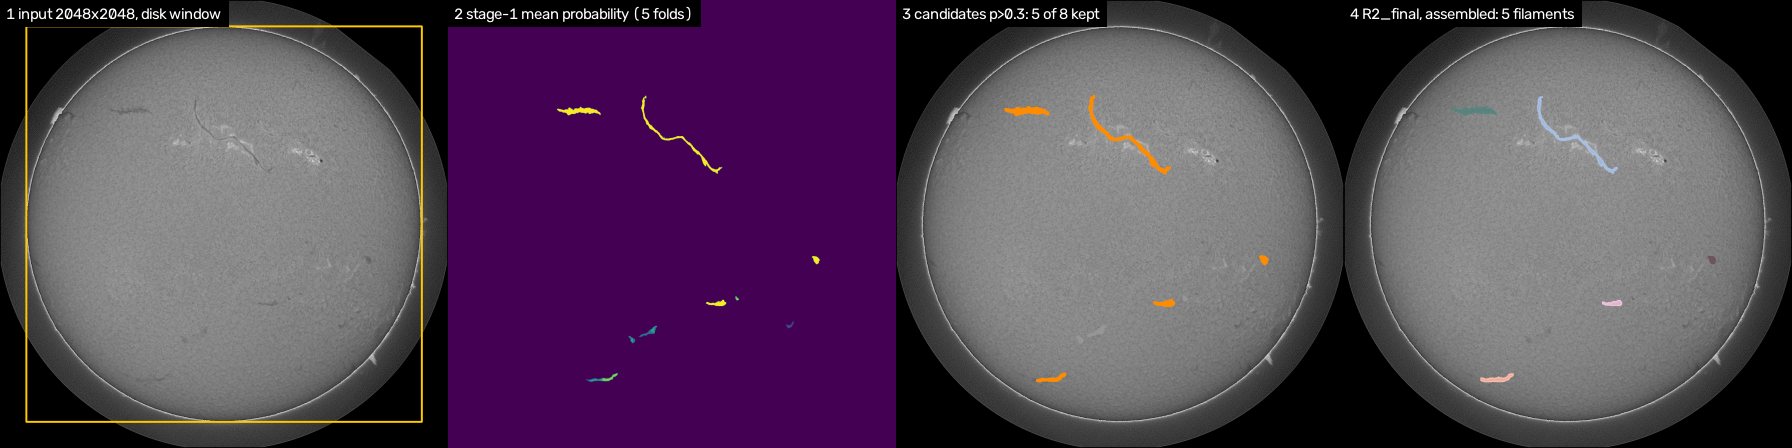

cleanup removed 0 px of detached parts | SE2: 3 fragment candidates -> 2 refined fragments, 1 added (score > 0.12744 and no overlap); scores: [0.3529999852180481, 0.0729999989271164]


In [3]:
from IPython.display import Image, display

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_bf16 = device.type == "cuda" and torch.cuda.get_device_capability(device)[0] >= 8   # same rule as R2B0.run
models = K.load_models(B0_WEIGHTS, device)
print(f"parameters + buffers per b0 model: {sum(t.numel() for t in models[0].state_dict().values()):,}")

# an image where SE2 adds small filaments (falls back to the first image if it is not in the folder)
first = next((p for p in U.list_test_images(TEST_DIR) if p.stem == "20120405130014Th"), IMAGES[0])
img = K.read_image(first)                          # uint8 2048x2048
r2 = R2B0.load_r2(R2_WEIGHT, device)
print(f"parameters + buffers of R2_final: {sum(t.numel() for t in r2.state_dict().values()):,}")
res = R2B0.predict_image(img, models, r2, device, use_bf16)
print(f"{first.name}: stage-1 instances (p>0.5, >=500 px) {len(res['existence'])} | candidates (p>0.3, >=20 px) "
      f"{len(res['boxes'])}, kept {len(res['kept'])} | R2 windows {res['n_windows']} | filaments "
      f"{len(res['instances'])}, areas (px):", sorted(int(c.sum()) for _, c in res["instances"]))
display(Image(data=U.r2b0_figure(img, res)))
# steps 5-6 on the same image: cleanup of the refined filaments, then the SE2 additions
se_net = SE.load_scorer(SE2_WEIGHT, device)
cover, n_px = np.zeros(img.shape, bool), 0
for (y0, x0, y1, x1), c in res["instances"]:
    full = np.zeros(img.shape, bool)
    full[y0:y1, x0:x1] = c
    cleaned = R2B0.drop_small_parts(full)
    n_px += int(full.sum() - cleaned.sum())
    cover |= cleaned
# SE2: refine the small fragments with R2_final, score the refined masks
fj, gate = SE.fragment_candidates(res["p16"], res["cand"], res["kept"])
fcp, _ = R2B0.refine_probs(r2, img, res["prob_u8"], res["cand"], res["boxes"], fj, device, use_bf16)
frags = R2B0.assemble({j: (y0, x0, p.astype(np.float32)) for j, (y0, x0, p) in fcp.items()}, min_area=100)
tau = SE.SE2_TAU
add, sc = SE.additions_refined(se_net, frags, img, res["p16"], gate, cover, tau, device)
what = f"SE2: {len(fj)} fragment candidates -> {len(frags)} refined fragments"
print(f"cleanup removed {n_px} px of detached parts | {what}, {len(add)} added "
      f"(score > {tau} and no overlap); scores:", np.round(np.sort(sc)[::-1], 3).tolist())
del se_net, r2, models

### 2b. The code of each step

The cells below print the code of every step **from the files the pipeline runs** (read with `ast`, so what is shown is
exactly what is executed above and in section 4). Training is section 3 (optional: `RUN_TRAINING`), evaluation section 6.

| Step | File | Functions and classes |
|---|---|---|
| Pre-processing | `src/filseg_infer.py` | `read_image`, `to_model_space` (disk crop `[120:1928]^2`, resize to 1024^2), `normalize` |
| Stage-1 model | `src/filseg_infer.py` | `ResNetEncoder`, `DecoderBlock`, `UnetDecoder`, `Unet` (U-Net, ResNet-101 encoder), `load_models` |
| Stage-1 probability | `src/filseg_infer.py`, `src/filseg_infer_r2b0.py` | `logits_to_full_prob`, `stage1` (mean of the 5 fold models) |
| Existence gate, candidates | `src/filseg_infer.py`, `src/filseg_infer_r2b0.py` | `components` (p > 0.5, >= 500 px), `candidates` (p > 0.3, >= 20 px) |
| R2 refinement | `src/filseg_infer_r2b0.py` | `load_r2`, `windows_for_box`, `orientation`, `make_input` (10 channels), `refine_probs` |
| Assembly, cleanup | `src/filseg_infer_r2b0.py` | `assemble` (merge IoU > 0.5, >= 300 px), `drop_small_parts` (< 20 px, then < 5 %) |
| SE2 | `src/filseg_infer_se.py` | constants (`SE2_TAU` = 0.12744), `build_scorer`, `fragment_candidates`, `crops_refined`, `additions_refined` |
| Output | `src/filseg_infer.py`, `src/filseg_infer_r2b0.py` | `encode` (COCO RLE), `write_rows`, `predict_image`, `run` |
| Training | `scripts/train_seg.py`, `scripts/train_refine.py`, `scripts/small_exist.py`, `scripts/se2.py` | data sets, losses, training loops, the SE2 scorer fit |
| Evaluation | `src/filseg/metrics.py`, `src/filseg/scorers.py` | the official per-set PQ (V0) and the pooled-set PQ (V1), used in section 6 |


In [4]:
import ast, re


def show(path, names, title):
    """Print the source of the named top-level functions/classes (or 'CONSTANTS' = the module constants) of a file."""
    src = (REPO / path).read_text()
    lines, tree = src.splitlines(), ast.parse(src)
    nodes = {n.name: n for n in tree.body if isinstance(n, (ast.FunctionDef, ast.ClassDef))}
    print("#" * 110 + f"\n# {title}  --  {path}\n" + "#" * 110)
    for name in names:
        if name == "CONSTANTS":
            first_def = min(n.lineno for n in nodes.values())
            start = next(i for i, l in enumerate(lines) if re.match(r"^H = W = 2048", l))
            print("\n".join(lines[start:first_def - 1]).rstrip() + "\n")
            continue
        n = nodes[name]
        start = n.decorator_list[0].lineno if n.decorator_list else n.lineno
        print("\n".join(lines[start - 1:n.end_lineno]) + "\n")


show("src/filseg_infer.py", ["read_image", "to_model_space", "normalize"], "PRE-PROCESSING")
show("src/filseg_infer.py", ["ResNetEncoder", "conv_bn_relu", "DecoderBlock", "UnetDecoder", "Unet", "load_models"],
     "STAGE-1 MODEL: U-Net with a ResNet-101 encoder (same layout as segmentation_models_pytorch 0.6.0)")
show("src/filseg_infer.py", ["logits_to_full_prob"], "STAGE-1 PROBABILITY at 2048^2")
show("src/filseg_infer_r2b0.py", ["CONSTANTS", "stage1"], "STAGE 1: mean of the 5 fold models; constants of the pipeline")

##############################################################################################################
# PRE-PROCESSING  --  src/filseg_infer.py
##############################################################################################################
def read_image(path) -> np.ndarray:
    img = cv2.imread(str(path), cv2.IMREAD_UNCHANGED | cv2.IMREAD_IGNORE_ORIENTATION)
    if img is None:
        raise IOError(f"cannot decode {path}")
    if img.ndim == 3:
        img = img[..., 0]
    if img.shape != (H, W):
        raise ValueError(f"{path}: expected {H}x{W}, got {img.shape}")
    return img

def to_model_space(img):
    return cv2.resize(img[CROP0:CROP1, CROP0:CROP1], (SIZE, SIZE), interpolation=cv2.INTER_AREA)

def normalize(xb_uint8):
    return (xb_uint8.float() / 255.0 - 0.30) / 0.22

##############################################################################################################
# STAGE-1 MODEL: U-Net with a ResNet-101 encoder (same layout as segment

In [5]:
show("src/filseg_infer.py", ["components"], "EXISTENCE GATE: components of p > 0.5 with >= 500 px")
show("src/filseg_infer_r2b0.py", ["candidates", "load_r2", "windows_for_box", "orientation", "_ctx", "_norm_img", "make_input",
                                  "refine_probs"], "CANDIDATES AND R2 NATIVE-RESOLUTION REFINEMENT")
show("src/filseg_infer_r2b0.py", ["assemble", "_drop_parts", "drop_small_parts"], "ASSEMBLY AND CLEANUP")

##############################################################################################################
# EXISTENCE GATE: components of p > 0.5 with >= 500 px  --  src/filseg_infer.py
##############################################################################################################
def components(prob, thr=THR, min_area=MIN_AREA):
    """8-connected components of prob > thr with >= min_area px, in label order -> list of (bbox, crop mask)."""
    n, lab, stats = cv2.connectedComponentsWithStats((prob > thr).astype(np.uint8), connectivity=8)[:3]
    out = []
    for k in range(1, n):
        x, y, w, h, a = stats[k]
        if a < max(min_area, 1):
            continue
        out.append(((y, x, y + h, x + w), lab[y:y + h, x:x + w] == k))
    return out

##############################################################################################################
# CANDIDATES AND R2 NATIVE-RESOLUTION REFINEMENT  --  src/filseg_infer_r2b0.py
############################

In [6]:
show("src/filseg_infer_se.py", ["CONSTANTS", "build_scorer", "load_scorer", "_crop_at", "to_input", "scores", "fragment_candidates",
                                "crops_refined", "additions_refined"], "SE2: SMALL FRAGMENTS, REDRAWN BY R2, SCORED, ADDED")
show("src/filseg_infer.py", ["runs_from_mask", "counts_to_string", "encode"], "OUTPUT: COCO compressed RLE")
show("src/filseg_infer_r2b0.py", ["write_rows", "predict_image", "run"], "THE WHOLE IMAGE AND THE WHOLE TEST SET")

##############################################################################################################
# SE2: SMALL FRAGMENTS, REDRAWN BY R2, SCORED, ADDED  --  src/filseg_infer_se.py
##############################################################################################################
H = W = 2048
THR, A_LO, A_HI, CROP = 0.5, 100, 500, 96
# SE2_TAU = 0.6 x 0.2124. 0.2124 = PQ/2 of the pipeline before this stage (out-of-fold, training data): the exact
# break-even of the official per-annotation-set metric. m = 0.6 maximises the leaderboard-type PQ (annotation sets of
# an image pooled) over the nested out-of-fold predictions of all 707 training images and is the leave-one-outer-fold-
# out choice in 4 of 5 folds (scripts/se2_analysis.py select, records/se2/analysis/threshold_v1.json). No test data.
SE2_TAU = 0.12744

def build_scorer() -> torch.nn.Module:
    m = torchvision.models.resnet101(weights=None)
    conv = torch.nn.Conv2d(4, 64, 7, 2, 3, bias=False)
    return

In [7]:
show("scripts/train_seg.py", ["TrainSet", "soft_dice_per_sample", "soft_dice_loss", "main"],
     "TRAINING, STAGE 1 (5 fold models; run by section 3 when RUN_TRAINING = True)")
show("scripts/train_refine.py", ["WinSet", "soft_dice", "main"], "TRAINING, R2 (native-resolution refinement)")
show("scripts/small_exist.py", ["build_scorer", "fit_predict"], "TRAINING, SE2 SCORER (architecture and fit)")
show("scripts/se2.py", ["fragments", "crops", "cmd_train"], "TRAINING, SE2: refined fragments, crops and the final scorer")

##############################################################################################################
# TRAINING, STAGE 1 (5 fold models; run by section 3 when RUN_TRAINING = True)  --  scripts/train_seg.py
##############################################################################################################
class TrainSet(torch.utils.data.Dataset):
    def __init__(self, cache_dir, files, aug=True, rot=15.0, seed=0):
        self.idx = json.load(open(cache_dir / "index.json"))
        self.cache_dir = cache_dir
        self.X = None
        self.T = None
        frow = {f: i for i, f in enumerate(self.idx["files"])}
        self.items = [(frow[f], self.idx["file_sets"][f]) for f in files]
        self.aug, self.rot, self.seed = aug, rot, seed
        self._main_rng = None

    def _rng(self):  # used only with num_workers=0
        if self._main_rng is None:
            self._main_rng = np.random.default_rng(self.seed)
        return self._main_rng

    def __len__(se

## 3. The whole pipeline: training, validation and model selection (records of the original runs, not re-run)

The challenge asks for predictions that can be reproduced **without retraining**, so this notebook does not train.
The files in `records/` were written during development by the scripts named below; the gated cell 3c lists the
exact commands of the whole pipeline (`entry_points.md` has the same commands with outputs and times).

### 3a. Stage 1: b0 (5-fold U-Net) and its post-processing

- `records/b0_r101_s1024/fold*/config.json`, `log.jsonl` and `summary.json` come from `scripts/train_seg.py`;
- the nested-CV choice of threshold and minimum area comes from `scripts/tune_post.py`;
- the pooled out-of-fold evaluation comes from `scripts/eval_oof.py`.

Validation PQ during training is computed on each fold's held-out images. It uses one model, threshold 0.5, and no size
filter or a 300 px size filter. The final post-processing (minimum area 500 px) was chosen afterwards by nested CV:
for each outer fold, the setting was selected on the other four folds.

In [8]:
REC = REPO / "records" / "b0_r101_s1024"
print("fold  train/val files  epochs  lr      batch  train min  val PQ (thr 0.5, >=300 px) at epoch 10/20/30/40/50/60")
for k in range(5):
    cfg = json.loads((REC / f"fold{k}" / "config.json").read_text())
    summ = json.loads((REC / f"fold{k}" / "summary.json").read_text())
    log = [json.loads(l) for l in (REC / f"fold{k}" / "log.jsonl").read_text().splitlines() if l.strip()]
    pq = {r["epoch"]: r["grid"]["t0.5_a300"]["PQ_pooled_host"] for r in log if "grid" in r}
    curve = " ".join(f"{pq[e]:.3f}" if e in pq else "  -  " for e in (10, 20, 30, 40, 50, 60))
    print(f"{k:>4}  {cfg['n_train_files']:>5}/{cfg['n_val_files']:<5}    {cfg['epochs']:>6}  {cfg['lr']:<6}  {cfg['bs']:>5}  "
          f"{summ['train_minutes']:>9.0f}  {curve}")
print(f"encoder {cfg['encoder']} (ImageNet init), input {cfg['size']}^2, loss BCE + {cfg['dice_w']} x soft Dice, "
      f"AdamW wd {cfg['wd']}, rotation +-{cfg['rot']} deg, seed {cfg['seed']}, GPU {cfg['gpu']}, torch {cfg['torch']}")

nested = json.loads((REC / "tune_post_cc_tt0.5_0-1-2-3-4_val_probs_last.json").read_text())
print("\nnested CV choice of (threshold, hysteresis seed threshold, min_area) per outer fold:",
      {k: tuple(v) for k, v in nested["nested"]["chosen"].items()})
print("per-fold out-of-fold PQ with the nested choice:",
      {k: round(v["PQ"], 3) for k, v in nested["per_fold_nested"].items()})
print(f"pooled out-of-fold PQ: {nested['nested']['PQ']:.4f} with the nested choice | "
      f"{nested['default_t05_noseed_a0']['PQ']:.4f} at thr 0.5 without the size filter")
oof = json.loads((REC / "eval_oof_cc_f01234_t0.5_a500.json").read_text())
a = oof["all"]
print(f"final setting (thr 0.5, min_area 500), {oof['n_records']} annotation-set records: PQ {a['PQ_pooled_host']:.4f}, "
      f"SQ {a['SQ_pooled']:.4f}, RQ {a['RQ_pooled']:.4f} (TP {a['TP']}, FP {a['FP']}, FN {a['FN']})")
print(f"files with 2-3 annotation sets: PQ {oof['multi_set_records']['PQ_pooled_host']:.4f}; one annotator scored "
      f"against another on the same files: PQ {oof['interannotator_reference_multi_set']['PQ']}")

fold  train/val files  epochs  lr      batch  train min  val PQ (thr 0.5, >=300 px) at epoch 10/20/30/40/50/60
   0    568/139          60  0.0003      4         81  0.371 0.393 0.405 0.416 0.424 0.422
   1    566/141          60  0.0003      4         57  0.361 0.357 0.379 0.386 0.391 0.393
   2    564/143          60  0.0003      4         78  0.330 0.351 0.379 0.397 0.397 0.402
   3    564/143          60  0.0003      4         57  0.344 0.368 0.379 0.389 0.403 0.400
   4    566/141          60  0.0003      4         62  0.357 0.384 0.397 0.403 0.417 0.422
encoder resnet101 (ImageNet init), input 1024^2, loss BCE + 1.0 x soft Dice, AdamW wd 0.0001, rotation +-15.0 deg, seed 2026, GPU NVIDIA RTX A6000, torch 2.6.0+cu124

nested CV choice of (threshold, hysteresis seed threshold, min_area) per outer fold: {'0': ('0.5', 'None', '500'), '1': ('0.5', 'None', '500'), '2': ('0.5', 'None', '500'), '3': ('0.5', 'None', '500'), '4': ('0.5', 'None', '500')}
per-fold out-of-fold PQ with the nes

### 3b. Nested validation of R2 and SE2, and the final refinement model R2_final

A refinement model trained on stage-1 outputs is a second-level (stacked) model, so it was validated with **nested
cross-validation** (`scripts/nested_stage1.py`, `scripts/nested_queue.py`, `scripts/nested_r2b0_eval.py`):
- for each outer fold k, 4 inner b0 models (`b0n_r101_s1024/hold{k,j}`, the unchanged b0 recipe on the 3 folds
  outside {k, j}) give the outer-train images an inner out-of-fold stage 1 and the fold-k images the mean of the
  4 inner models (`b0n_ens`), which is also the matched baseline `B_ens` (t0.5, 8-conn, >= 500 px);
- an R2 model `R2n_context/fold{k}` is trained on the outer-train windows only and evaluated on fold k with exactly the
  test-time recipe (existence, candidates, assembly);
- 10 inner b0 runs + 5 R2n runs = 15 GPU runs; leakage and consistency checks A-E per outer fold
  (`records/nested_r2b0/verify_o*.json`, all passed);
- the SE2 scorer of outer fold k is trained only on fragments from inner stage-1 models and 20 inner R2 models that
  never saw fold k (`scripts/run_r2nn.sh`, `scripts/se2.py`, `records/se2/`).

The adoption rule of R2 was registered before any nested result. R2 improved PQ in every fold but **failed two
conditions** (thin-region precision, and a leave-one-annotator-out thin-precision aspect falling below the human
level), so under the rule it was not adopted. The team then decided, post hoc, to adopt it; this is stated in
`docs/validation.md`. The public leaderboard was not used for this decision. R2_final was trained once with the same
recipe on all 707 training files, with the 5-fold b0 out-of-fold stage 1 (`records/R2_final_context/all/`). The
cleanup stage (D-051, D-058) then passed its own pre-registered rule; SE2 failed one condition at its registered
threshold; its final threshold (0.12744, chosen by V1 without the evaluated fold) fails four of the six conditions and
was adopted by a post-hoc team decision (`docs/validation.md`).

Scorer note: V0 is the organisers' self-evaluation notebook (one record per annotation set and image). V1 is our
*hypothesis* for the hidden leaderboard scorer (one record per image, all annotation sets' instances concatenated,
one-to-one matching); the public scores of our earlier submissions matched it within rounding (final CSV: V1 0.381 out of fold, public 0.37), but it is not confirmed.

In [9]:
NR = REPO / "records" / "nested_r2b0"
ev = json.loads((NR / "eval_summary.json").read_text())
c = ev["R2nb0_vs_B_ens"]
A, B = c["A"], c["B"]
print(f"nested OOF, {c['n_files']} files / {c['n_records']} annotation-set records / 5 outer folds; "
      f"verify A-E passed for all outer folds: {all(json.loads((NR / f'verify_o{k}.json').read_text())['all_ok'] for k in range(5))}")
print(f"PQ (V0): B_ens {A['PQ']:.4f} -> R2nb0 {B['PQ']:.4f}, diff {c['file_boot']['PQ']['diff']:+.4f} "
      f"[{c['file_boot']['PQ']['ci95'][0]:+.4f}, {c['file_boot']['PQ']['ci95'][1]:+.4f}] (file bootstrap)")
print("per outer fold diff:", {k: round(v["diff"], 4) for k, v in c["per_fold"].items()},
      "| folds 2-4 alone:", round(ev["R2nb0_vs_B_ens_folds234"]["file_boot"]["PQ"]["diff"], 4))
print(f"files better / worse: {c['per_file_sign']['better']} / {c['per_file_sign']['worse']} (sign test p = "
      f"{c['per_file_sign']['sign_test_p']:.1e}) | review set PQ {c['review_set']['A']:.3f} -> {c['review_set']['B']:.3f}")
print(f"thin-region recall {A['thin_recall']:.3f} -> {B['thin_recall']:.3f} | thin-region precision "
      f"{A['thin_precision']:.3f} -> {B['thin_precision']:.3f} (diff {c['file_boot']['thin_precision']['diff']:+.3f} "
      f"[{c['file_boot']['thin_precision']['ci95'][0]:+.3f}, {c['file_boot']['thin_precision']['ci95'][1]:+.3f}])")
asp = ev["loao"]["aspects"]["thin_precision_colocated"]
print(f"LOAO thin_precision_colocated: human {asp['human']:.3f}, B_ens {asp['B_ens']:.3f}, R2nb0 {asp['R2nb0']:.3f}")
print("pre-registered rule:", {k: v for k, v in ev["rule"].items()})
print("-> rule outcome: R2 not adopted by the rule; adopted by a stated post-hoc decision (docs/validation.md)")

v = json.loads((NR / "scorer_v1_check.json").read_text())
print("\nnested OOF PQ under both scorers (707 files)   V0 (official notebook)   V1 (hypothesis)")
for name, key in (("stage 1 + existence gate (B_ens)", "B_ens"), ("+ R2 refinement and assembly", "R2nb0")):
    print(f"  {name:<44} {v[key]['V0']:.4f}                   {v[key]['V1']:.4f}")

RF = REPO / "records" / "R2_final_context" / "all"
cfg = json.loads((RF / "config.json").read_text())
log = [json.loads(l) for l in (RF / "log.jsonl").read_text().splitlines() if l.strip()]
summ = json.loads((RF / "summary.json").read_text())
print(f"\nR2_final: variant {cfg['variant']} ({cfg['channels']} input channels), all {len(set(cfg['train_folds']))} folds "
      f"({cfg['n_train_windows']} windows of {cfg['win']}^2), {cfg['epochs']} epochs, batch {cfg['bs']}, lr {cfg['lr']}, "
      f"seed {cfg['seed']}, stage 1 = 5-fold b0 OOF ({cfg['stage1']}); train loss {log[0]['train_loss']:.3f} -> "
      f"{log[-1]['train_loss']:.3f}; {summ['train_minutes']:.1f} min, peak GPU memory {summ['peak_mem_gb']:.1f} GB")
gpu_min = sum(json.loads((NR / d / r / "summary.json").read_text())["train_minutes"]
              for d in ("b0n_r101_s1024", "R2n_context") for r in sorted(os.listdir(NR / d)))
print(f"nested validation: 15 GPU runs, {gpu_min / 60:.1f} GPU-hours of training (records/nested_r2b0/*/*/summary.json)")

nested OOF, 707 files / 1154 annotation-set records / 5 outer folds; verify A-E passed for all outer folds: True
PQ (V0): B_ens 0.4093 -> R2nb0 0.4243, diff +0.0150 [+0.0104, +0.0197] (file bootstrap)
per outer fold diff: {'0': 0.0129, '1': 0.0161, '2': 0.0101, '3': 0.0211, '4': 0.0151} | folds 2-4 alone: 0.0154
files better / worse: 426 / 253 (sign test p = 3.2e-11) | review set PQ 0.369 -> 0.380
thin-region recall 0.427 -> 0.454 | thin-region precision 0.510 -> 0.493 (diff -0.017 [-0.027, -0.007])
LOAO thin_precision_colocated: human 0.566, B_ens 0.576, R2nb0 0.548
pre-registered rule: {'pq_diff_ge_0': True, 'thin_recall_higher': True, 'thin_precision_higher': False, 'sign_test': True, 'review_set_not_lower': True, 'no_loao_aspect_newly_below_human': False, 'all_5_folds_present': True, 'table_covers_all_val_files': True, 'loao_covers_all_multiset_files': True, 'no_loao_aspect_undetermined': True, 'verify_all_ok_incl_r2n': True, 'ADOPT': False}
-> rule outcome: R2 not adopted by the r

In [10]:
# 3c. The whole pipeline as commands, run from the repository root. Re-training is optional and OFF (set
# RUN_TRAINING = True to train from scratch; section 4 then predicts with the new models). It needs
# requirements.txt (training packages included), a GPU with ~14 GB, the training data in MAGFiLO_1.0_Kaggle_2026/train/, and torchvision's
# ImageNet ResNet-101 checkpoint (README.md, "Training from scratch"). Everything is written to outputs/ and logs/;
# the stored weights in weights/ are not touched.
RUN_TRAINING = False
PAIRS = ["2,3", "2,4", "0,2", "1,2", "3,4", "0,3", "1,3", "0,4", "1,4", "0,1"]      # nested_stage1.PAIR_ORDER
PIPELINE = {
    "A. stage 1: b0, 5-fold U-Net (records/b0_r101_s1024/; 57-81 min and 14 GB GPU per fold)": [
        ["scripts/train_seg.py", "--exp", "b0_r101_s1024", "--fold", str(k), "--epochs", "60", "--val_every", "5", "--workers", "6"]
        for k in range(5)] + [
        ["scripts/tune_post.py", "--exp", "b0_r101_s1024", "--folds", "0,1,2,3,4", "--probs", "val_probs_last.npz"],
        ["scripts/eval_oof.py", "--exp", "b0_r101_s1024", "--folds", "0,1,2,3,4", "--thr", "0.5", "--min_area", "500"]],
    "B. nested CV of the R2 refinement (records/nested_r2b0/; 15 GPU runs). nested_queue.py launches, in "
    "dependency order, exactly the jobs listed after it (logs: records/nested_r2b0/nested_queue.log, nested_eval.log)": [
        ["scripts/build_refine_cache.py"],                                   # refine_v1: candidates from the 5-fold b0 OOF
        # our run: --gpus 0,1 (restarted on GPU 0 only); with one GPU add --inner_first. The CPU-affinity defaults
        # (--cores_gpu0 16-21 --cores_gpu1 22-27 --cores_cpu 28-31) are those of our 32-core server: adjust them.
        ["scripts/nested_queue.py", "--gpus", "0"],
        ["scripts/scorer_v1_check.py"]],                                     # V0 / V1 OOF PQ of B_ens, R2nb0
    "   B'. the jobs of nested_queue.py (for reference; the queue runs them)": [
        ["scripts/train_seg.py", "--exp", "b0n_r101_s1024", "--holdout", p, "--epochs", "60", "--val_every", "60", "--workers", "6",
         "--no_best"] for p in PAIRS] + [
        c for k in range(5) for c in (["scripts/nested_stage1.py", "ens", "--outer", str(k)],
                                      ["scripts/nested_stage1.py", "cache", "--outer", str(k), "--workers", "4"],
                                      ["scripts/nested_stage1.py", "verify", "--outer", str(k)])] + [
        ["scripts/train_refine.py", "--variant", "r2", "--fold", str(k), "--epochs", "30", "--exp", "R2n_context",
         "--cache", f"outputs/cache/refine_nested_o{k}"] for k in (2, 3, 4, 0, 1)] + [
        ["scripts/nested_stage1.py", "verify", "--outer", str(k)] for k in range(5)] + [
        ["scripts/nested_r2b0_eval.py", "table", "--workers", "4"], ["scripts/nested_r2b0_eval.py", "loao", "--workers", "4"],
        ["scripts/nested_r2b0_eval.py", "analyse"]],
    "C. final R2 model and cleanup validation (records/R2_final_context/all/; 36 min, 5.2 GB GPU)": [
        ["scripts/train_refine.py", "--variant", "r2", "--all", "--epochs", "30", "--exp", "R2_final_context"]] + [
        ["scripts/" + s, c] for s in ("eval_dual.py", "fragment_cleanup.py", "island_cleanup.py")
        for c in ("table", "loao", "analyse")],
    "D. per-fold break-even tau_k = PQ/2 of the pipeline before SE2 on the outer-train folds, and the scorer recipe "
    "that SE2 reuses (scripts/small_exist.py; < 1 min GPU)": [
        ["scripts/small_exist.py", c] for c in ("cands", "train")],
    "E. SE2, the final small-filament stage (records/se2/): per outer fold k the nested cache, 4 inner R2 models on "
    "the folds outside {k, j} (scripts/run_r2nn.sh runs these and deletes each cache after use; ~10 GPU-h), then the "
    "scorers, the evaluation and the threshold chosen by V1 (m = 0.6 -> 0.12744)": [
        c for k in range(5) for c in ([["scripts/nested_stage1.py", "cache", "--outer", str(k), "--workers", "4"]] + [
            ["scripts/train_refine.py", "--variant", "r2", "--fold", str(k), "--inner", str(j), "--epochs", "30",
             "--exp", "R2nn_context", "--cache", f"outputs/cache/refine_nested_o{k}"] for j in range(5) if j != k])] + [
        ["scripts/se2.py", "data", "--source", "eval"], ["scripts/se2.py", "data", "--source", "inner"],
        ["scripts/se2.py", "train"]] + [["scripts/se2.py", s] for s in ("eval", "loao", "analyse")] + [
        ["scripts/se2_analysis.py", "sweep"], ["scripts/a_eval.py", "eval"], ["scripts/a_eval.py", "loao"]] + [
        ["scripts/se2_analysis.py", s] for s in ("select", "classify")],
}
if RUN_TRAINING:
    import subprocess
    for title, cmds in PIPELINE.items():
        if title.lstrip().startswith("B'"):
            continue                                                       # run by nested_queue.py
        for cmd in cmds:
            subprocess.run([sys.executable, *cmd], cwd=REPO, check=True)
    # predict with the models just trained instead of the stored ones (section 4 uses these names)
    B0_WEIGHTS = [REPO / "outputs" / "exps" / "b0_r101_s1024" / f"fold{k}" / "last.pt" for k in range(5)]
    R2_WEIGHT = REPO / "outputs" / "exps" / "R2_final_context" / "all" / "last.pt"
    SE2_WEIGHT = REPO / "outputs" / "research" / "se2" / "scorer_final.pt"
    print("section 4 will use the newly trained models:", [os.path.relpath(p, REPO) for p in B0_WEIGHTS + [R2_WEIGHT, SE2_WEIGHT]])
else:
    print("training skipped (RUN_TRAINING = False). The whole pipeline, run from the repository root:")
    for title, cmds in PIPELINE.items():
        print("\n" + title)
        for cmd in cmds:
            print("  python", " ".join(cmd))

training skipped (RUN_TRAINING = False). The whole pipeline, run from the repository root:

A. stage 1: b0, 5-fold U-Net (records/b0_r101_s1024/; 57-81 min and 14 GB GPU per fold)
  python scripts/train_seg.py --exp b0_r101_s1024 --fold 0 --epochs 60 --val_every 5 --workers 6
  python scripts/train_seg.py --exp b0_r101_s1024 --fold 1 --epochs 60 --val_every 5 --workers 6
  python scripts/train_seg.py --exp b0_r101_s1024 --fold 2 --epochs 60 --val_every 5 --workers 6
  python scripts/train_seg.py --exp b0_r101_s1024 --fold 3 --epochs 60 --val_every 5 --workers 6
  python scripts/train_seg.py --exp b0_r101_s1024 --fold 4 --epochs 60 --val_every 5 --workers 6
  python scripts/tune_post.py --exp b0_r101_s1024 --folds 0,1,2,3,4 --probs val_probs_last.npz
  python scripts/eval_oof.py --exp b0_r101_s1024 --folds 0,1,2,3,4 --thr 0.5 --min_area 500

B. nested CV of the R2 refinement (records/nested_r2b0/; 15 GPU runs). nested_queue.py launches, in dependency order, exactly the jobs listed after

### 3d. Efficiency (inference per 2048x2048 image, end to end incl. reading, post-processing and RLE)

| | GPU: NVIDIA RTX A6000, bf16 autocast | CPU only, fp32 |
|---|---|---|
| final pipeline (5 stage-1 models + R2_final + SE2) | **about 3.4 s** (614 s for 180 images, `reference/submission_r2b0_se2.meta.json`) | about 14 s with 4 threads |

Training cost (RTX A6000): stage 1 57-81 min per fold (14 GB); R2_final 36 min (5.2 GB); SE2 scorers under a minute;
nested validation 15 runs of about 31 min each (7.8 GPU-hours, cell 3b); SE2 inner R2 models 20 x 30 min (~10 GPU-h).

## 4. Predict all test images and write the submission CSV

In [11]:
t0, last = time.time(), [0.0]
def log(msg):   # the device line, then progress about once a minute, and the final line
    if not msg[:1].isdigit() or time.time() - last[0] > 60 or msg.startswith(f"{len(IMAGES)}/"):
        print(f"[{time.time() - t0:6.0f} s] {msg}", flush=True)
        last[0] = time.time()

summary = R2B0.run(TEST_DIR, B0_WEIGHTS, R2_WEIGHT, SE2_WEIGHT, OUT_CSV, limit=N_LIMIT, log=log)
elapsed = time.time() - t0
try:
    import resource
    peak_rss_gb = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 2**20      # Linux: KiB
except Exception:
    peak_rss_gb = float("nan")
print(f"wrote {rel(OUT_CSV)}: {summary['rows']} filaments ({summary['se_added']} added by SE2) in "
      f"{summary['images_with_predictions']} of "
      f"{summary['images']} images | device {summary['device']}, bf16 {summary['bf16']} | "
      f"{elapsed:.0f} s ({elapsed / max(summary['images'], 1):.1f} s per image) | peak RSS {peak_rss_gb:.1f} GB")

[     6 s] device=cuda bf16_autocast=True stage-1 models=5 refinement model=R2_final images=180


[    68 s] 20/180 images, 165 filaments (32 added by SE2), 63 s


[   129 s] 39/180 images, 346 filaments (62 added by SE2), 124 s


[   190 s] 58/180 images, 524 filaments (82 added by SE2), 184 s


[   251 s] 76/180 images, 717 filaments (114 added by SE2), 245 s


[   312 s] 93/180 images, 931 filaments (151 added by SE2), 307 s


[   374 s] 113/180 images, 1089 filaments (178 added by SE2), 368 s


[   435 s] 135/180 images, 1202 filaments (203 added by SE2), 429 s


[   495 s] 160/180 images, 1274 filaments (220 added by SE2), 489 s


[   549 s] 180/180 images, 1381 filaments (253 added by SE2), 543 s


wrote outputs/submission_r2b0_se2.csv: 1381 filaments (253 added by SE2) in 177 of 180 images | device cuda, bf16 True | 549 s (3.1 s per image) | peak RSS 1.7 GB


In [12]:
# format checks on the written file (R2B0.run already checked RLE round trips and that no two filaments overlap)
sub = U.read_submission(OUT_CSV)
all_stems = {p.stem for p in U.list_test_images(TEST_DIR)}
ids = [fid for rows in sub.values() for fid, _ in rows]
assert len(ids) == len(set(ids)), "duplicate filament_id"
assert set(sub) <= all_stems, "filament_id refers to an unknown image"
assert all(rle and '"' not in rle and "'" not in rle for rows in sub.values() for _, rle in rows), "bad RLE string"
print(f"format OK: {len(ids)} rows, {len(sub)} images with predictions; first rows:")
for fid, rle in [r for rows in list(sub.values())[:1] for r in rows][:3]:
    print(f"  {fid},{rle[:48]}...")

format OK: 1381 rows, 177 images with predictions; first rows:
  20110120105534Ch_0,\_\h23lo14M7I1ePNDQo1<lPNHTo17iPNLWo1>jPN]OQo1i0...
  20110120105534Ch_1,jj^o12mo12M2O1M2000N3O0O101000000000000000ko9LWP...


## 5. Compare with the submitted reference CSV

The reference CSV is the CSV that was submitted to Kaggle: `reference/submission_r2b0_se2.csv`, 1,381 filaments,
public leaderboard 0.37. It was produced by `src/filseg_infer_r2b0.run` on an NVIDIA RTX A6000 with bf16 autocast and
deterministic cuDNN. Filaments are matched by overlap (IoU > 0.5, unique as in Panoptic Quality), never by
`filament_id`. Only the images processed above are compared.

The verdict thresholds (`src/reproduce_utils.py::VERDICT_TOLERANCE`) were fixed before the CPU reproduction runs.
**Bit-identical** means every mask matches exactly. **Reproduced within numerical tolerance** requires all of:
- the same set of images has predictions;
- at least 97% of the reference filaments are matched;
- at most 3% of filaments appear or disappear;
- the median IoU of matched filaments is at least 0.95.

On CPU (fp32) a few pixels with p close to a threshold flip relative to the bf16 reference. Several steps react to
this (candidates at 0.3 and 20 px, existence at 0.5 and 500 px, refined masks at 0.5, merging at IoU 0.5, 300 px), and
the refinement model itself runs in bf16 on the GPU, so masks can differ a little (typically IoU 0.95-1.0).

In [13]:
cmp = U.compare_submissions(OUT_CSV, REF_CSV, images=[p.stem for p in IMAGES])
print(f"images compared: {cmp['images_compared']} | with predictions: new {cmp['images_with_rows_new']}, "
      f"reference {cmp['images_with_rows_ref']} | same image set: {cmp['same_images_with_predictions']}")
print(f"filaments: new {cmp['rows_new']}, reference {cmp['rows_ref']} | matched (IoU>0.5) {cmp['matched']} | "
      f"bit-identical masks {cmp['bit_identical_masks']}")
print("IoU of matched filaments: min {iou_min:.4f}  p1 {iou_p01:.4f}  p5 {iou_p05:.4f}  p25 {iou_p25:.4f}  "
      "median {iou_median:.4f}  mean {iou_mean:.4f}".format(**cmp))
print(f"pixel disagreement (xor / reference foreground): {cmp['pixel_disagreement_fraction']:.5f} | "
      f"agreement PQ (reference as ground truth): {cmp['agreement_pq']:.4f}")
print("images with a different number of rows (image, new, reference):", cmp["images_with_different_row_count"] or "none")
print("disappeared (reference only):", cmp["disappeared"] or "none")
print("appeared (new only):", cmp["appeared"] or "none")
print("\nVERDICT:", U.verdict(cmp))
report = OUT_CSV.with_name(OUT_CSV.stem + "_vs_reference.json")
json.dump(dict(cmp, reference=rel(REF_CSV), verdict=U.verdict(cmp), device=summary["device"],
               bf16=summary["bf16"], seconds=round(elapsed), torch=torch.__version__, threads=torch.get_num_threads()),
          open(report, "w"), indent=1, default=str)
print("saved", rel(report))

images compared: 180 | with predictions: new 177, reference 177 | same image set: True
filaments: new 1381, reference 1381 | matched (IoU>0.5) 1381 | bit-identical masks 1381
IoU of matched filaments: min 1.0000  p1 1.0000  p5 1.0000  p25 1.0000  median 1.0000  mean 1.0000
pixel disagreement (xor / reference foreground): 0.00000 | agreement PQ (reference as ground truth): 1.0000
images with a different number of rows (image, new, reference): none
disappeared (reference only): none
appeared (new only): none

VERDICT: BIT-IDENTICAL to the reference submission
saved outputs/submission_r2b0_se2_vs_reference.json


## 6. Evaluation that runs in this notebook

The metric code is `src/filseg/metrics.py` (V0, identical to the organisers' self-evaluation notebook: one record per
annotation set and image, every IoU > 0.5 pair a true positive) and `src/filseg/scorers.py` (V1: the sets of an image
pooled, one-to-one matching); mean Dice is computed on the union masks of each record.

- **Runs here:** each stage-1 fold model never saw its own fold, so stage 1 + the existence gate is evaluated out of
  fold on the training images with the weights in `weights/` (needs `MAGFiLO_1.0_Kaggle_2026/train/`).
  `FILSEG_EVAL_N` images per fold (default 20; 0 = all 707); `FILSEG_EVAL=0` skips the section.
- **From the records:** R2 and the SE2 scorer are stacked on stage-1 outputs, so the whole pipeline was validated with
  nested cross-validation (40 inner models, about 18 GPU-hours; `docs/validation.md`). Those inner models are not
  stored; their out-of-fold results are printed from `records/`.

In [14]:
RUN_EVAL = os.environ.get("FILSEG_EVAL", "1") == "1"
EVAL_N = int(os.environ.get("FILSEG_EVAL_N", "20"))
TRAIN_JSON = TEST_DIR.parent.parent / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
if RUN_EVAL and not TRAIN_JSON.is_file():
    print(f"training annotations not found ({TRAIN_JSON}): the live out-of-fold check is skipped; it needs the full "
          "competition data (train/ next to test/). The records of the original runs are printed below.")
if RUN_EVAL and TRAIN_JSON.is_file():
    import pandas as pd
    os.environ.setdefault("FILSEG_ROOT", str(TEST_DIR.parent.parent.parent))   # src/filseg/data.py reads <root>/MAGFiLO_1.0_Kaggle_2026/
    from filseg import seg
    from filseg.metrics import EvalConfig, InstanceSet, evaluate_image
    from filseg.scorers import v1_counts
    split = pd.read_csv(REPO / "outputs" / "splits" / "folds_v1.csv")
    cfg = EvalConfig(compute_boundary=False, compute_pair_boundary=False, compute_thin=False)
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    bf16 = dev.type == "cuda" and torch.cuda.get_device_capability(dev)[0] >= 8
    v0, v1, dice, n_img = np.zeros(4), np.zeros(4), [], 0
    for k in range(5):
        model = K.load_models([REPO / "weights" / f"b0_fold{k}.pt"], dev)      # trained without fold k
        files = sorted(split[split.fold == k].file_name)[: EVAL_N or None]
        gts = seg.gt_records(files)
        by = {}
        for rid, g in gts.items():
            by.setdefault(rid.split("-", 1)[1], {})[rid] = g
        for f in files:
            stem = f[:-5]
            img = K.read_image(seg.D.train_image_path(f))
            x = K.normalize(torch.from_numpy(K.to_model_space(img)[None]).to(dev))[:, None]
            with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16, enabled=bf16):
                lg = model[0](x).float()[:, 0]
            p = K.logits_to_full_prob(lg)[0].astype(np.float16).astype(np.float32)
            comps = K.components(p)                                         # p > 0.5, 8-connected, >= 500 px
            P = InstanceSet._build((2048, 2048), [b for b, _ in comps], [c for _, c in comps]) if comps else InstanceSet.empty()
            sets = by.get(stem, {})
            pu = P.union() if len(P) else np.zeros((2048, 2048), bool)
            for rid, G in sets.items():
                r = evaluate_image(G, P, cfg, return_instances=False)[0]
                v0 += [r["tp_host"], r["fp_host"], r["fn_host"], r["sum_iou_host"]]
                gu = G.union() if len(G) else np.zeros((2048, 2048), bool)
                dice.append(2 * (gu & pu).sum() / max(gu.sum() + pu.sum(), 1))
            v1 += np.array(v1_counts([sets[r] for r in sorted(sets)], P), float)
            n_img += 1
        del model
    pq = lambda t: t[3] / max(t[0] + .5 * t[1] + .5 * t[2], 1e-12)
    print(f"stage 1 + existence gate, out of fold, {n_img} images / {len(dice)} annotation-set records "
          f"(FILSEG_EVAL_N={EVAL_N} per fold): PQ V0 {pq(v0):.4f}, V1 {pq(v1):.4f}, mean Dice {np.mean(dice):.4f}")
    print("all 707 images (records/b0_r101_s1024/eval_oof_*.json): V0", 
          round(json.loads((REPO / "records" / "b0_r101_s1024" / "eval_oof_cc_f01234_t0.5_a500.json").read_text())["all"]["PQ_pooled_host"], 4))
import pandas as pd
ab = pd.read_csv(REPO / "records" / "report_analyses" / "ablation.csv") if RUN_EVAL else None
if ab is not None:
    print("\nthe whole pipeline, nested out of fold, 707 images (records/report_analyses/ablation.csv):")
    for _, r in ab.iterrows():
        print(f"  {r.stage.replace(chr(10), ' '):<34} V0 {r.V0:.4f}   V1 {r.V1:.4f}")
    rub = json.loads((REPO / "records" / "report_analyses" / "rubric_summary.json").read_text())["final_se2"]
    print(f"  final pipeline: mean Dice {rub['sem_dice_mean']:.4f}, one-to-many {rub['gt_1toN']}, many-to-one {rub['pred_Nto1']}")

stage 1 + existence gate, out of fold, 100 images / 178 annotation-set records (FILSEG_EVAL_N=20 per fold): PQ V0 0.4102, V1 0.3506, mean Dice 0.6803
all 707 images (records/b0_r101_s1024/eval_oof_*.json): V0 0.4099

the whole pipeline, nested out of fold, 707 images (records/report_analyses/ablation.csv):
  stage 1 + gate (nested B_ens)      V0 0.4093   V1 0.3493
  + R2 refinement                    V0 0.4243   V1 0.3589
  + cleanup                          V0 0.4249   V1 0.3595
  + SE2 (final pipeline)             V0 0.4316   V1 0.3814
  final pipeline: mean Dice 0.6726, one-to-many 397, many-to-one 289
